# ShopSmart - Collaborative Filtering

## 1. User-Based Collaborative Filtering

This notebook implements collaborative filtering using
the user-item rating matrix.

Steps:
1. Build a sparse user-item matrix
2. Compute user similarities using cosine similarity
3. Identify nearest neighbors using KNN
4. Recommend products based on neighbors' ratings

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

PROCESSED_DIR = Path("../data/processed")

train = pd.read_csv(PROCESSED_DIR / "train.csv")

products = pd.read_json(
    PROCESSED_DIR / "products_preprocessed.jsonl",
    lines=True
)

print("Training interactions:", train.shape)
print("Products:", products.shape)

Training interactions: (132836, 4)
Products: (2000, 13)


In [2]:
# Create user and product index mappings
user_ids = train["user_id"].unique()
product_ids = products["parent_asin"].unique()

user_to_index = {
    user: i for i, user in enumerate(user_ids)
}

product_to_index = {
    product: i for i, product in enumerate(product_ids)
}

# Convert IDs into numerical indices
user_indices = train["user_id"].map(user_to_index)
product_indices = train["parent_asin"].map(product_to_index)

# Build sparse user-item matrix
user_item_matrix = csr_matrix(
    (
        train["rating"].values,
        (user_indices, product_indices)
    ),
    shape=(len(user_ids), len(product_ids))
)

print("User-Item Matrix:", user_item_matrix.shape)
print("Known ratings:", user_item_matrix.nnz)

User-Item Matrix: (7368, 2000)
Known ratings: 132836


In [3]:
user_knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=31
)

user_knn.fit(user_item_matrix)

print("User-Based KNN model ready!")

User-Based KNN model ready!


In [4]:
def recommend_user_based(user_id, top_n=10, k=30):

    if user_id not in user_to_index:
        return pd.DataFrame()

    idx = user_to_index[user_id]

    distances, indices = user_knn.kneighbors(
        user_item_matrix[idx],
        n_neighbors=min(k + 1, len(user_ids))
    )

    neighbors = []
    similarities = []

    for neighbor_idx, distance in zip(
        indices[0], distances[0]
    ):
        similarity = max(0.0, 1.0 - distance)

        if neighbor_idx != idx and similarity > 0:
            neighbors.append(neighbor_idx)
            similarities.append(similarity)

        if len(neighbors) == k:
            break

    if not neighbors:
        return pd.DataFrame()

    # Retrieve ratings given by similar users
    neighbor_ratings = user_item_matrix[neighbors]

    weights = np.array(similarities)

    # Weighted average of neighbors' ratings
    weighted_sum = np.asarray(
        neighbor_ratings.multiply(weights[:, None]).sum(axis=0)
    ).ravel()

    rating_mask = neighbor_ratings.copy()
    rating_mask.data = np.ones_like(rating_mask.data)

    weight_sum = np.asarray(
        rating_mask.multiply(weights[:, None]).sum(axis=0)
    ).ravel()

    scores = np.divide(
        weighted_sum,
        weight_sum,
        out=np.zeros_like(weighted_sum),
        where=weight_sum > 0
    )

    # Exclude products already rated by the user
    seen_indices = user_item_matrix[idx].indices
    scores[seen_indices] = -np.inf

    # Exclude products with no neighbor ratings
    scores[weight_sum == 0] = -np.inf

    valid_indices = np.where(np.isfinite(scores))[0]

    if len(valid_indices) == 0:
        return pd.DataFrame()

    top_indices = valid_indices[
        np.argsort(scores[valid_indices])[::-1][:top_n]
    ]

    recommended_asins = product_ids[top_indices]

    recommendations = pd.DataFrame({
        "parent_asin": recommended_asins,
        "predicted_score": scores[top_indices]
    })

    return recommendations.merge(
        products[["parent_asin", "title", "main_category"]],
        on="parent_asin",
        how="left"
    )

In [5]:
# Select a user with sufficient training history
user_id = (
    train.groupby("user_id")
    .size()
    .sort_values(ascending=False)
    .index[0]
)

print("Selected user:", user_id)

print("\nUser rating history:")

display(
    train[train["user_id"] == user_id]
    .merge(
        products[["parent_asin", "title"]],
        on="parent_asin"
    )[["title", "rating"]]
    .head(10)
)

print("\nTop 10 User-Based recommendations:")

display(
    recommend_user_based(
        user_id,
        top_n=10,
        k=30
    )
)

Selected user: AGRHKDNSRJ3CT5ST75KGSCD4WA5A

User rating history:


,title,rating
0,ASUS TUF SABERTOOTH 990FX R2.0 Socket AM3+ DDR...,5.0
1,NZXT Sentry 2 Touch Screen Fan Controller Meter,5.0
2,"Case Logic Laptop Sleeve 17-17.3"", Black",5.0
3,CORSAIR Hydro Series H105 AIO Liquid CPU Coole...,5.0
4,Logitech MK520 Wireless Keyboard and Mouse Com...,5.0
5,SAMSUNG 850 EVO 250GB 2.5-Inch SATA III Intern...,5.0
6,MagicFiber Extra Large Microfiber Cleaning Clo...,5.0
7,Amazon Basics 3.5mm Aux Audio Cable for Stereo...,5.0
8,"Amazon Basics 11.6-Inch Laptop Sleeve, Protect...",5.0
9,Amazon Basics High-Speed HDMI Cable 2-Pack - 6...,5.0



Top 10 User-Based recommendations:


,parent_asin,predicted_score,title,main_category
0,B0772Y1FVD,5.0,32GB Samsung Evo Plus Micro SDHC Class 10 UHS-...,Computers
1,B0B3N4KFY3,5.0,Monoprice Premium Two-Channel Audio Cable - 25...,Home Audio & Theater
2,B077V2BF3C,5.0,"Moread HDMI to VGA, 2 Pack, Gold-Plated HDMI t...",Computers
3,B01KT301YC,5.0,Amazon Basics 5-Pack DisplayPort to HDMI Displ...,Computers
4,B00XAG2C16,5.0,Cable Matters Mini DisplayPort to DVI Cable (M...,All Electronics
5,B0771VF9TJ,5.0,AKASO EK7000 4K30FPS 20MP Action Camera Ultra ...,Camera & Photo
6,B01DOB6Y5Q,5.0,Samsung 32GB 80MB/s EVO Select Micro SDHC Memo...,Computers
7,B017T99JPG,5.0,Bose SoundLink Mini Bluetooth Speaker II (Carbon),Home Audio & Theater
8,B01HR9VS4I,5.0,eBoot 100 Pieces Adhesive Cable Clips Wire Cli...,Tools & Home Improvement
9,B00DZYEXPQ,5.0,"Dust-Off Compressed Gas Duster, Pack of 4",Office Products


## 2. Item-Based Collaborative Filtering

We compute item-item similarities using the transposed
user-item rating matrix.

Recommendations are generated from products previously
liked by the user.

The model uses cosine similarity and KNN.

In [6]:
# Transpose the user-item matrix
item_user_matrix = user_item_matrix.T.tocsr()

print("Item-User Matrix:", item_user_matrix.shape)

# Item-Based KNN
item_knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=31
)

item_knn.fit(item_user_matrix)

print("Item-Based KNN model ready!")

Item-User Matrix: (2000, 7368)
Item-Based KNN model ready!


In [7]:
def recommend_item_based(user_id, top_n=10, k=30):

    if user_id not in user_to_index:
        return pd.DataFrame()

    user_idx = user_to_index[user_id]
    user_ratings = user_item_matrix[user_idx]

    # Products already rated by the user
    seen_items = user_ratings.indices
    seen_ratings = user_ratings.data

    # Only use positively rated products
    liked_mask = seen_ratings >= 4

    liked_items = seen_items[liked_mask]
    liked_ratings = seen_ratings[liked_mask]

    if len(liked_items) == 0:
        return pd.DataFrame()

    scores = np.zeros(len(product_ids))
    similarity_sums = np.zeros(len(product_ids))

    for item_idx, rating in zip(liked_items, liked_ratings):

        distances, indices = item_knn.kneighbors(
            item_user_matrix[item_idx],
            n_neighbors=min(k + 1, len(product_ids))
        )

        for neighbor_idx, distance in zip(
            indices[0], distances[0]
        ):
            if neighbor_idx == item_idx:
                continue

            similarity = max(0.0, 1.0 - distance)

            if similarity <= 0:
                continue

            # Higher ratings indicate stronger preference
            preference = rating - 3

            scores[neighbor_idx] += (
                similarity * preference
            )

            similarity_sums[neighbor_idx] += similarity

    # Regularization reduces the influence of
    # recommendations supported by very few neighbors
    valid = similarity_sums > 0

    scores[valid] = (
        scores[valid] /
        (similarity_sums[valid] + 2.0)
    )

    scores[~valid] = -np.inf

    # Exclude products already rated
    scores[seen_items] = -np.inf

    valid_indices = np.where(np.isfinite(scores))[0]

    top_indices = valid_indices[
        np.argsort(scores[valid_indices])[::-1][:top_n]
    ]

    recommendations = pd.DataFrame({
        "parent_asin": product_ids[top_indices],
        "recommendation_score": scores[top_indices]
    })

    return recommendations.merge(
        products[["parent_asin", "title", "main_category"]],
        on="parent_asin",
        how="left"
    )

In [8]:
print("Selected user:", user_id)

print("\nTop 10 Item-Based recommendations:")

item_recommendations = recommend_item_based(
    user_id,
    top_n=10,
    k=30
)

display(item_recommendations)

Selected user: AGRHKDNSRJ3CT5ST75KGSCD4WA5A

Top 10 Item-Based recommendations:


,parent_asin,recommendation_score,title,main_category
0,B011BRUOMO,1.106671,SanDisk Ultra 32GB microSDHC UHS-I Card with A...,Computers
1,B0BGNG1294,1.055332,"Amazon Basics HDMI Cable, 18Gbps High-Speed, 4...",Home Audio & Theater
2,B0BS2ZMHCL,0.827688,Western Digital 4TB WD Blue PC Internal Hard D...,Computers
3,B01K8B8YA8,0.752789,Echo Dot (2nd Generation) - Smart speaker with...,Amazon Devices
4,B07TZP1SD3,0.735284,Corsair Air Series AF120 LED Quiet Edition Hig...,Computers
5,B0BV93KQZR,0.700976,Cooler Master Hyper 212 EVO V2 CPU Air Cooler ...,Computers
6,B071R715MZ,0.675834,64GB EVO Select Memory Card and Sabrent SuperS...,Computers
7,B07P9V8GSH,0.627128,SanDisk Ultra 32GB UHS-I/Class 10 Micro SDHC M...,Computers
8,B0033Z2BAQ,0.626711,ASUS 24x DVD-RW Serial-ATA Internal OEM Optica...,All Electronics
9,B09N42GVF7,0.614488,Corsair CMK32GX4M2F4000C19 Vengeance LPX 32GB ...,Computers


## 3. Collaborative Filtering Evaluation

We evaluate User-Based and Item-Based Collaborative Filtering
on the same validation users as the Content-Based model.

Metrics:
- Precision@10
- Recall@10
- Hit Rate@10
- Catalog Coverage

In [9]:
validation = pd.read_csv(
    PROCESSED_DIR / "validation.csv"
)

# Same evaluation protocol as Content-Based
validation_positive = validation[
    validation["rating"] >= 4
].copy()

users_with_positive_history = set(
    train.loc[train["rating"] >= 4, "user_id"]
)

validation_positive = validation_positive[
    validation_positive["user_id"].isin(
        users_with_positive_history
    )
]

eval_users = validation_positive.sample(
    n=min(300, len(validation_positive)),
    random_state=42
)

print("Eligible users:", len(validation_positive))
print("Evaluation users:", len(eval_users))

Eligible users: 6122
Evaluation users: 300


In [10]:
# Precompute nearest neighbors for all products
item_distances, item_neighbors = item_knn.kneighbors(
    item_user_matrix,
    n_neighbors=31
)

print("Item neighbors precomputed!")
print("Shape:", item_neighbors.shape)

Item neighbors precomputed!
Shape: (2000, 31)


In [11]:
def recommend_item_based_fast(user_id, top_n=10, k=30):

    if user_id not in user_to_index:
        return pd.DataFrame()

    user_idx = user_to_index[user_id]
    user_ratings = user_item_matrix[user_idx]

    seen_items = user_ratings.indices
    seen_ratings = user_ratings.data

    liked_mask = seen_ratings >= 4
    liked_items = seen_items[liked_mask]
    liked_ratings = seen_ratings[liked_mask]

    if len(liked_items) == 0:
        return pd.DataFrame()

    scores = np.zeros(len(product_ids))
    similarity_sums = np.zeros(len(product_ids))

    for item_idx, rating in zip(liked_items, liked_ratings):

        neighbors_added = 0

        for neighbor_idx, distance in zip(
            item_neighbors[item_idx],
            item_distances[item_idx]
        ):
            if neighbor_idx == item_idx:
                continue

            similarity = max(0.0, 1.0 - distance)

            if similarity <= 0:
                continue

            preference = rating - 3

            scores[neighbor_idx] += similarity * preference
            similarity_sums[neighbor_idx] += similarity

            neighbors_added += 1
            if neighbors_added >= k:
                break

    valid = similarity_sums > 0

    scores[valid] = (
        scores[valid] /
        (similarity_sums[valid] + 2.0)
    )

    scores[~valid] = -np.inf
    scores[seen_items] = -np.inf

    valid_indices = np.where(np.isfinite(scores))[0]

    top_indices = valid_indices[
        np.argsort(scores[valid_indices])[::-1][:top_n]
    ]

    return pd.DataFrame({
        "parent_asin": product_ids[top_indices],
        "recommendation_score": scores[top_indices]
    })

In [12]:
def evaluate_recommender(recommend_func, eval_data, k=10):

    hits = []
    all_recommended = set()
    recommendation_lengths = []

    for _, row in eval_data.iterrows():

        user_id = row["user_id"]
        relevant_product = row["parent_asin"]

        recommendations = recommend_func(
            user_id,
            top_n=k
        )

        if recommendations.empty:
            recommended_ids = set()
        else:
            recommended_ids = set(
                recommendations["parent_asin"]
            )

        hit = int(relevant_product in recommended_ids)

        hits.append(hit)
        all_recommended.update(recommended_ids)
        recommendation_lengths.append(len(recommended_ids))

    hit_rate = np.mean(hits)

    return {
        "Precision@10": hit_rate / k,
        "Recall@10": hit_rate,
        "Hit Rate@10": hit_rate,
        "Coverage": len(all_recommended) / len(product_ids),
        "Avg Recommendations": np.mean(recommendation_lengths)
    }

In [13]:
print("Evaluating User-Based...")

user_results = evaluate_recommender(
    recommend_user_based,
    eval_users
)

print("Evaluating Item-Based...")

item_results = evaluate_recommender(
    recommend_item_based_fast,
    eval_users
)

comparison_cf = pd.DataFrame(
    [user_results, item_results],
    index=["User-Based KNN", "Item-Based KNN"]
)

display(comparison_cf)

Evaluating User-Based...
Evaluating Item-Based...


,Precision@10,Recall@10,Hit Rate@10,Coverage,Avg Recommendations
User-Based KNN,0.000333,0.003333,0.003333,0.514,10.0
Item-Based KNN,0.004667,0.046667,0.046667,0.219,10.0


## 4. User-Based KNN Improvement

The initial User-Based model performs poorly because items
rated by only one neighbor can receive very high scores.

We introduce:
- Minimum neighbor support
- Score regularization
- Comparison with the original model

In [14]:
def recommend_user_based_v2(user_id, top_n=10, k=30):

    if user_id not in user_to_index:
        return pd.DataFrame()

    idx = user_to_index[user_id]

    distances, indices = user_knn.kneighbors(
        user_item_matrix[idx],
        n_neighbors=min(k + 1, len(user_ids))
    )

    neighbors = []
    similarities = []

    for neighbor_idx, distance in zip(indices[0], distances[0]):

        similarity = max(0.0, 1.0 - distance)

        if neighbor_idx != idx and similarity > 0:
            neighbors.append(neighbor_idx)
            similarities.append(similarity)

        if len(neighbors) >= k:
            break

    if not neighbors:
        return pd.DataFrame()

    neighbor_ratings = user_item_matrix[neighbors]
    weights = np.array(similarities)

    weighted_sum = np.asarray(
        neighbor_ratings.multiply(weights[:, None]).sum(axis=0)
    ).ravel()

    rating_mask = neighbor_ratings.copy()
    rating_mask.data = np.ones_like(rating_mask.data)

    weight_sum = np.asarray(
        rating_mask.multiply(weights[:, None]).sum(axis=0)
    ).ravel()

    support = np.asarray(
        rating_mask.sum(axis=0)
    ).ravel()

    # Regularized recommendation score
    scores = weighted_sum / (weight_sum + 2.0)

    # Require at least two neighbors
    scores[support < 2] = -np.inf

    # Exclude already rated products
    seen_indices = user_item_matrix[idx].indices
    scores[seen_indices] = -np.inf

    valid_indices = np.where(np.isfinite(scores))[0]

    top_indices = valid_indices[
        np.argsort(scores[valid_indices])[::-1][:top_n]
    ]

    return pd.DataFrame({
        "parent_asin": product_ids[top_indices],
        "recommendation_score": scores[top_indices],
        "neighbor_support": support[top_indices]
    })

In [15]:
print("Evaluating improved User-Based KNN...")

user_v2_results = evaluate_recommender(
    recommend_user_based_v2,
    eval_users
)

comparison_user = pd.DataFrame(
    [user_results, user_v2_results],
    index=["User-Based Original", "User-Based Improved"]
)

display(comparison_user)

Evaluating improved User-Based KNN...


,Precision@10,Recall@10,Hit Rate@10,Coverage,Avg Recommendations
User-Based Original,0.000333,0.003333,0.003333,0.5140,10.0
User-Based Improved,0.003000,0.030000,0.030000,0.2415,10.0


## 5. Extended Validation

We evaluate the collaborative filtering models on a larger
sample of 1,000 users.

We compare:
- User-Based KNN (Original)
- User-Based KNN (Improved)
- Item-Based KNN

All models use the same validation users.

In [16]:
# Reproducible sample of 1,000 validation users
eval_users_1000 = validation_positive.sample(
    n=min(1000, len(validation_positive)),
    random_state=42
)

print("Evaluation users:", len(eval_users_1000))

models = {
    "User-Based Original": recommend_user_based,
    "User-Based Improved": recommend_user_based_v2,
    "Item-Based KNN": recommend_item_based_fast
}

results_1000 = {}

for name, func in models.items():
    print(f"Evaluating {name}...")

    results_1000[name] = evaluate_recommender(
        func,
        eval_users_1000,
        k=10
    )

comparison_1000 = pd.DataFrame.from_dict(
    results_1000,
    orient="index"
)

display(comparison_1000)

Evaluation users: 1000
Evaluating User-Based Original...
Evaluating User-Based Improved...
Evaluating Item-Based KNN...


,Precision@10,Recall@10,Hit Rate@10,Coverage,Avg Recommendations
User-Based Original,0.0009,0.009,0.009,0.8050,10.0
User-Based Improved,0.0036,0.036,0.036,0.3865,10.0
Item-Based KNN,0.0058,0.058,0.058,0.3670,10.0


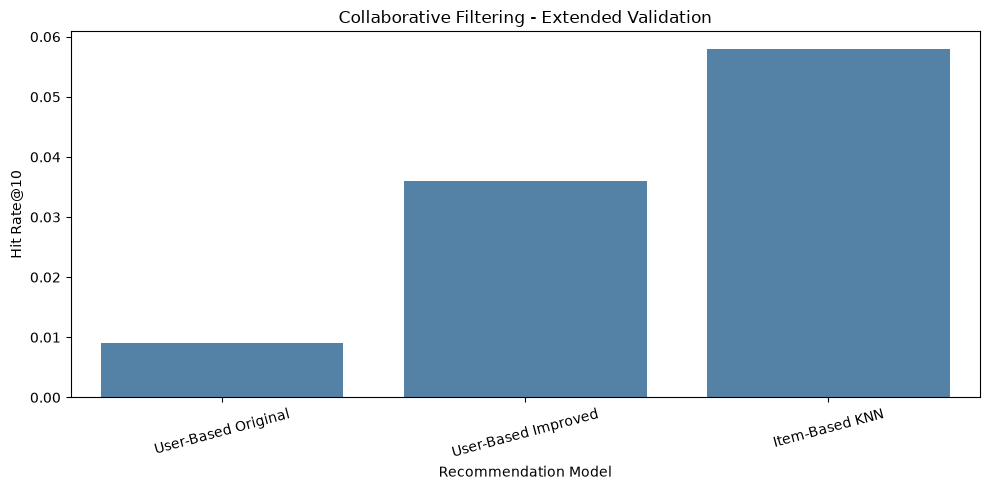

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    x=comparison_1000.index,
    y=comparison_1000["Hit Rate@10"],
    color="steelblue"
)

plt.title("Collaborative Filtering - Extended Validation")
plt.xlabel("Recommendation Model")
plt.ylabel("Hit Rate@10")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Final Model Comparison on Validation Data

We compare Content-Based, Popularity-Based, User-Based and
Item-Based recommendation systems on the same 1,000 users.

We analyze both recommendation accuracy and catalog coverage.

In [18]:
# Load Content-Based and Popularity results
content_results = pd.read_csv(
    PROCESSED_DIR / "content_popularity_validation.csv"
)

# Get Collaborative Filtering results
collaborative_results = comparison_1000[
    ["Precision@10", "Hit Rate@10", "Coverage"]
].reset_index().rename(columns={"index": "Model"})

# Rename models consistently
collaborative_results["Model"] = (
    collaborative_results["Model"].replace({
        "User-Based Original": "User-Based KNN V1",
        "User-Based Improved": "User-Based KNN V2",
        "Item-Based KNN": "Item-Based KNN"
    })
)

# Combine all results
final_comparison = pd.concat(
    [content_results, collaborative_results],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    "Hit Rate@10",
    ascending=False
).reset_index(drop=True)

display(final_comparison)

,Model,Precision@10,Hit Rate@10,Coverage
0,Item-Based KNN,0.0058,0.058,0.3670
1,Popularity Baseline,0.0040,0.040,0.0080
2,User-Based KNN V2,0.0036,0.036,0.3865
3,Content-Based TF-IDF,0.0030,0.030,0.4965
4,User-Based KNN V1,0.0009,0.009,0.8050


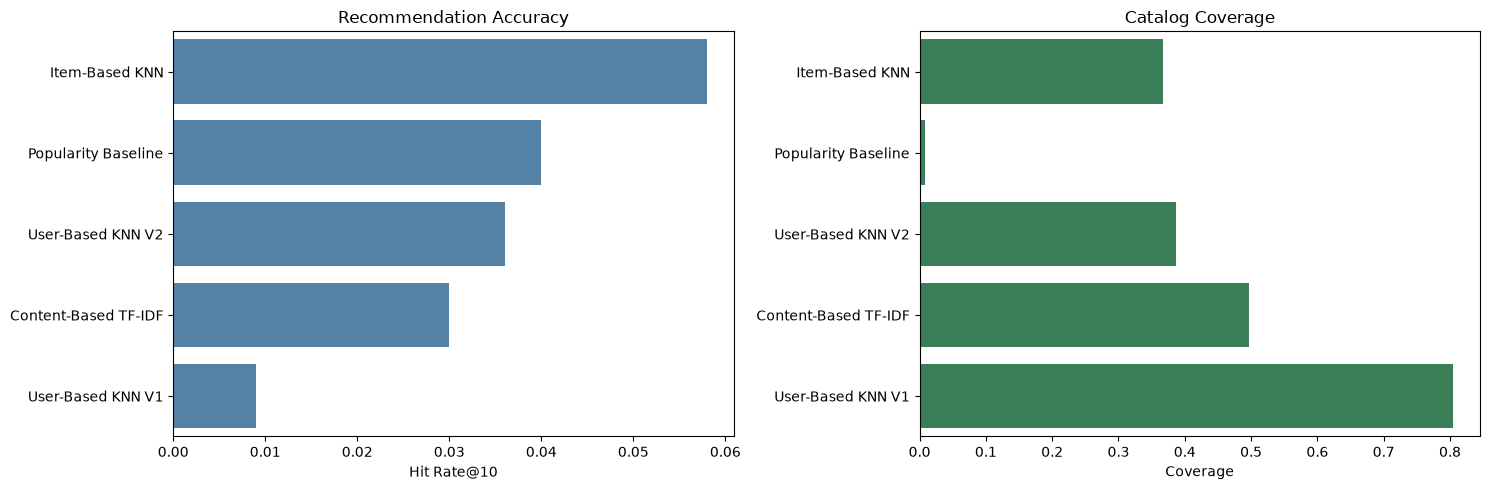

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=final_comparison,
    x="Hit Rate@10",
    y="Model",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Recommendation Accuracy")
axes[0].set_xlabel("Hit Rate@10")
axes[0].set_ylabel("")

sns.barplot(
    data=final_comparison,
    x="Coverage",
    y="Model",
    ax=axes[1],
    color="seagreen"
)

axes[1].set_title("Catalog Coverage")
axes[1].set_xlabel("Coverage")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [20]:
final_comparison.to_csv(
    PROCESSED_DIR / "model_comparison_validation.csv",
    index=False
)

fig.savefig(
    PROCESSED_DIR / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


## 7. Final Evaluation on Test Set

We evaluate the previously selected recommendation models
on unseen test interactions.

The models remain unchanged after validation.

We use the same test users across all recommendation approaches.

In [21]:
test = pd.read_csv(
    PROCESSED_DIR / "test.csv"
)

# Positive test interactions
test_positive = test[
    test["rating"] >= 4
].copy()

# Users with positive training history
eligible_users = set(
    train.loc[train["rating"] >= 4, "user_id"]
)

test_positive = test_positive[
    test_positive["user_id"].isin(eligible_users)
]

# Reproducible test sample
eval_test = test_positive.sample(
    n=min(1000, len(test_positive)),
    random_state=123
)

print("Eligible test users:", len(test_positive))
print("Selected test users:", len(eval_test))

Eligible test users: 6018
Selected test users: 1000


In [22]:
print("Evaluating User-Based KNN V2 on test...")

user_test_results = evaluate_recommender(
    recommend_user_based_v2,
    eval_test,
    k=10
)

print("Evaluating Item-Based KNN on test...")

item_test_results = evaluate_recommender(
    recommend_item_based_fast,
    eval_test,
    k=10
)

cf_test_comparison = pd.DataFrame(
    [user_test_results, item_test_results],
    index=["User-Based KNN V2", "Item-Based KNN"]
)

display(cf_test_comparison)

Evaluating User-Based KNN V2 on test...
Evaluating Item-Based KNN on test...


,Precision@10,Recall@10,Hit Rate@10,Coverage,Avg Recommendations
User-Based KNN V2,0.0027,0.027,0.027,0.3885,10.0
Item-Based KNN,0.0035,0.035,0.035,0.3910,10.0


In [23]:
cf_test_comparison.to_csv(
    PROCESSED_DIR / "collaborative_test_results.csv"
)

# Save test sample identifiers to ensure
# identical evaluation users across notebooks
eval_test[["user_id", "parent_asin", "rating"]].to_csv(
    PROCESSED_DIR / "test_users_sample.csv",
    index=False
)

print("Collaborative test results saved!")
print("Test sample saved!")

Collaborative test results saved!
Test sample saved!
